# Les 7 groupes de frieze — art génératif de symétrie 1D

Une **frieze** (bandeau) est un motif qui se répète le long d'une ligne : une bordure, un liseré, une frise décorative. La question que pose ce carnet est : **combien de façons distinctes un motif peut-il se répéter** tout en conservant des symétries (translation, réflexion, rotation, glissement) ?

La réponse, fondée en cristallographie, est **exactement 7**. Ce sont les **7 groupes de frieze**. Ce carnet les dessine tous, en **art génératif** : à chaque exécution, le motif de base est tiré au hasard, donc **les illustrations ne se répètent jamais** — mais les 7 *types* de symétrie restent bien distingués.

> **Provenance** : carnet de la série *Symmetry* (nouveauté du dépôt — aucun contenu de symétrie crystallographique n'existait). Distillation de l'idée de [aberke/coloring-book](https://github.com/aberke/coloring-book) (« A Coloring Book about Group Theory »), **ré-implémentée indépendamment** : la classification des groupes de frieze est un **fait mathématique**, pas l'expression protégée de l'auteur ; le repo est cité comme *inspiration*, ni son code JS ni ses assets ne sont copiés (issue #25324, gate licence, voie a).

In [1]:
import numpy as np
import matplotlib
import matplotlib.pyplot as plt

# Reproductible par defaut ; le mode "generatif" (seed=None) tire un motif nouveau a chaque exec
SEED = 7
print(f"numpy {np.__version__}, matplotlib {matplotlib.__version__} -- seed {SEED}")

numpy 2.5.4, matplotlib 3.11.1 -- seed 7


## Les 7 groupes, et leurs symétries

Chaque groupe contient toujours la **translation** de période (le motif se répète le long de la ligne). Les 7 groupes se distinguent par les **autres** opérations qu'ils contiennent :

| Groupe | Opérations (outre la translation) | Copies / période | Idée visuelle |
|--------|-----------------------------------|:---:|--------------|
| `p1`   | aucune | 1 | simple répétition à l'identique |
| `p11g` | glissement-réflexion | 2 | un jumeau retourné, décalé d'un demi-période |
| `p1m1` | miroir vertical | 2 | un jumeau en miroir (axe perpendiculaire) |
| `p11m` | miroir horizontal | 2 | un jumeau en miroir (axe parallèle) |
| `p2`   | rotation 180° | 2 | un jumeau à l'envers |
| `p2mg` | miroir + glissement | 4 | la cellule fondamentale double |
| `p2mm` | deux miroirs (→ rotation) | 4 | la cellule fondamentale double |

On va maintenant **construire** chaque bande : on part d'un petit motif de base asymétrique, et on l'applique par toutes les opérations du groupe, puis par translation de période en période.

In [2]:
# --- Operations de symetrie sur une bande de periode L ----------------------
# Le motif de base vit dans la cellule fondamentale [0, L] x [-h, h].
# Chaque operation est une transformation (x, y) -> (x', y').
def _id(x, y, L):   return (x, y)             # identite
def _Mv(x, y, L):   return (-x, y)            # miroir vertical  (axe perpendiculaire)
def _Mh(x, y, L):   return (x, -y)            # miroir horizontal (axe parallele)
def _R(x, y, L):    return (-x, -y)           # rotation 180 degres
def _G(x, y, L):    return (x + L/2, -y)      # glissement-reflexion (demie periode + retour)
def _MvG(x, y, L):  return (-x + L/2, -y)     # = Mv o G  (mod translation)
def _GR(x, y, L):   return (-x + L/2, y)      # = G o R   (mod translation)

# Chaque groupe = la liste des *copies* du motif dans la cellule fondamentale.
# C'est precisement cet ensemble qui distingue visuellement les 7 groupes.
# (p1m1 = miroir vertical, p11m = miroir horizontal : deux groupes distincts ;
#  l'ancien « p2gg » n'en était pas un — sa rotation composée au glissement
#  produit un miroir vertical, il se confond donc avec p2mg.)
FRIZE = {
    "p1":   [_id],
    "p11g": [_id, _G],
    "p1m1": [_id, _Mv],
    "p11m": [_id, _Mh],
    "p2":   [_id, _R],
    "p2mg": [_id, _Mv, _G, _MvG],
    "p2mm": [_id, _Mv, _Mh, _R],
}
N_COPIES = {g: len(v) for g, v in FRIZE.items()}
print("copies par periode :", N_COPIES)

# --- Petit motif de base asymetrique (art generatif) ------------------------
def make_motif(seed, n=6):
    """n points colores dans la cellule fondamentale, asymetriques par construction."""
    rng = np.random.default_rng(seed)
    x = rng.uniform(0.15, 0.85, n)          # dans [0, L], L = 1 ici
    y = rng.uniform(-0.5, 0.5, n)
    c = rng.uniform(0.1, 0.9, (n, 3))
    return np.column_stack([x, y]), c

copies par periode : {'p1': 1, 'p11g': 2, 'p1m1': 2, 'p11m': 2, 'p2': 2, 'p2mg': 4, 'p2mm': 4}


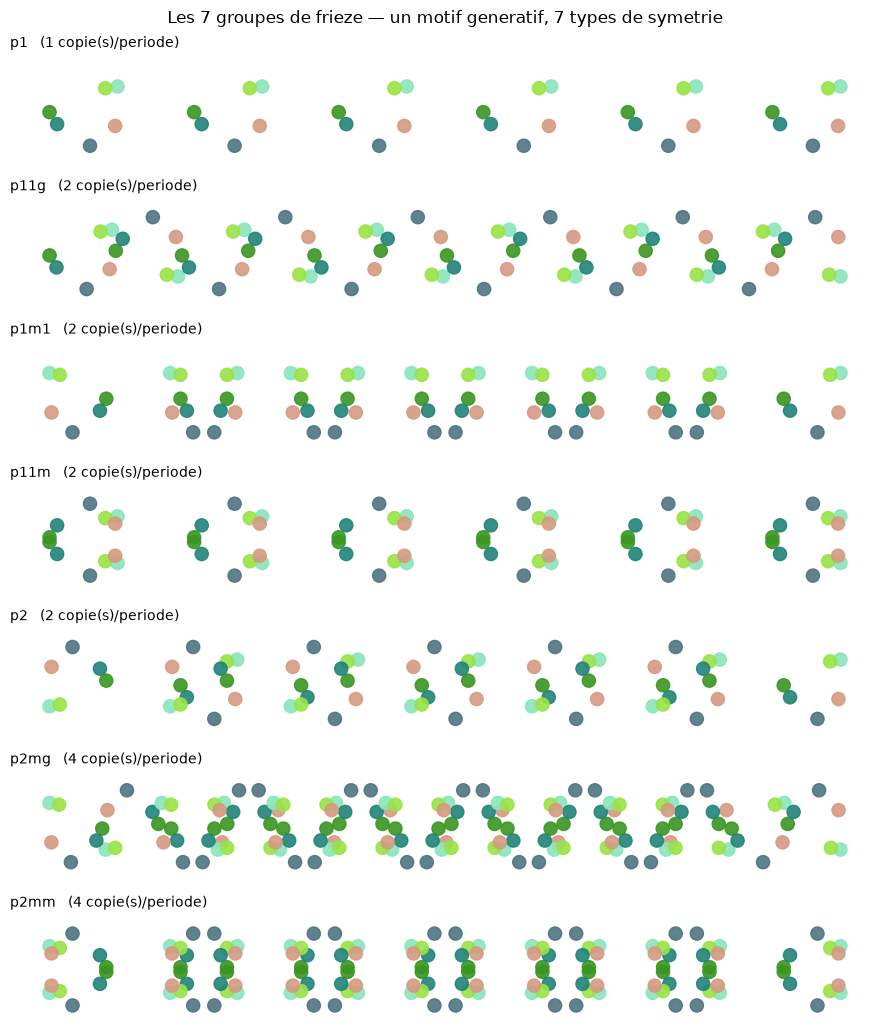

In [3]:
def render_frieze(group, motif_pts, motif_cols, L=1.0, n_periods=6):
    """Remplit la fenetre [0, n_periods*L] par l'orbite du motif sous le groupe."""
    xs, ys, cs = [], [], []
    for k in range(n_periods):
        for (px, py), col in zip(motif_pts, motif_cols):
            for t in FRIZE[group]:
                qx, qy = t(px, py, L)
                xs.append(qx + k * L)
                ys.append(qy)
                cs.append(col)
    return np.array(xs), np.array(ys), np.array(cs)

groups = list(FRIZE)
fig, axes = plt.subplots(len(groups), 1, figsize=(9, 1.5 * len(groups)))
for ax, g in zip(axes, groups):
    pts, cols = make_motif(SEED)                    # meme motif de base pour les 7 bandes
    xs, ys, cs = render_frieze(g, pts, cols)
    ax.scatter(xs, ys, c=cs, s=90, alpha=0.9)
    ax.set_title(f"{g}   ({N_COPIES[g]} copie(s)/periode)", loc="left", fontsize=10)
    ax.set_ylim(-0.75, 0.75)
    ax.set_yticks([]); ax.set_xticks([])
    for s in ax.spines.values():
        s.set_visible(False)
fig.suptitle("Les 7 groupes de frieze — un motif generatif, 7 types de symetrie")
fig.tight_layout()
plt.show()

### Lecture du résultat

Les 7 bandes partagent le **même motif de base** (tiré au hasard, seed `SEED`) ; seul l'**ensemble des opérations** change. On voit directement :

- `p1` : le motif se répète à l'identique ;
- `p11g` : un jumeau **retourné** apparaît, décalé d'un **demi-période** (c'est le glissement — le trait le plus subtil à repérer) ;
- `p1m1` / `p11m` / `p2` : un jumeau en **miroir vertical** / **miroir horizontal** / **à l'envers** ;
- les deux groupes à 4 copies (`p2mg`, `p2mm`) : la cellule fondamentale est plus riche, d'où une densité de points double.

C'est tout l'intérêt de l'art génératif : la **structure** (le groupe) est fixe et classifiable, l'**instance** (le motif) est nouvelle à chaque tirage. Re-exécuter la cellule de rendu (avec un autre `SEED`) donne 7 bandes *différentes* mais *du même type*.

In [4]:
# --- Signature de chaque groupe ---------------------------------------------
# Une « signature » = (copies, glissement, miroir vertical, miroir horizontal).
# On la déduit du groupe lui-même (les opérations qu'il contient) : c'est elle
# que l'exercice 1 exploite pour reconnaître un groupe.
GLIDE_OPS = (_G, _MvG, _GR)

def signature(g):
    """Signature 4-composantes d'un groupe de frieze, deduite de FRIZE[g]."""
    ops = FRIZE[g]
    return (len(ops),
            any(op in GLIDE_OPS for op in ops),   # glissement ?
            _Mv in ops,                            # miroir vertical ?
            _Mh in ops)                            # miroir horizontal ?

for g in FRIZE:
    print(f"{g:6s}  {signature(g)}")
sigs = [signature(g) for g in FRIZE]
print(f"\nLes 7 signatures sont distinctes : {len(set(sigs)) == 7}")

p1      (1, False, False, False)
p11g    (2, True, False, False)
p1m1    (2, False, True, False)
p11m    (2, False, False, True)
p2      (2, False, False, False)
p2mg    (4, True, True, False)
p2mm    (4, False, True, True)

Les 7 signatures sont distinctes : True


## Exercice 1 — Reconnaître un groupe à sa signature

Une bande peut être caractérisée par sa **signature** à 4 composantes : le nombre de **copies** par période, la présence d'un **glissement**, la présence d'un **miroir vertical**, et la présence d'un **miroir horizontal**. Les 7 signatures sont distinctes :

| Groupe | (copies, glissement, miroir_v, miroir_h) |
|--------|:----------------------------:|
| `p1`   | (1, F, F, F) |
| `p11g` | (2, V, F, F) |
| `p1m1` | (2, F, V, F) |
| `p11m` | (2, F, F, V) |
| `p2`   | (2, F, F, F) |
| `p2mg` | (4, V, V, F) |
| `p2mm` | (4, F, V, V) |

Complétez `identify(n_copies, a_glide, a_mirror_v, a_mirror_h)` pour qu'elle renvoie le nom du groupe.

In [5]:
def identify(n_copies: int, a_glide: bool, a_mirror_v: bool, a_mirror_h: bool) -> str:
    """Renvoie le nom du groupe de frieze a partir de sa signature (4 composantes).

    Parametres
    ----------
    n_copies   : nombre de copies du motif dans la cellule fondamentale
    a_glide    : la bande contient-elle un glissement-reflexion ?
    a_mirror_v : la bande contient-elle un miroir vertical ?
    a_mirror_h : la bande contient-elle un miroir horizontal ?

    Retour
    ------
    str : le nom du groupe parmi les cles de FRIZE
    """
    # TODO etudiant : completer a partir du tableau des signatures ci-dessus
    result = None  # TODO etudiant
    return result

# Auto-test (doit passer une fois la fonction completee) :
# assert identify(1, False, False, False) == "p1"
# assert identify(2, True,  False, False) == "p11g"
# assert identify(2, False, True,  False) == "p1m1"
# assert identify(2, False, False, True ) == "p11m"
# assert identify(2, False, False, False) == "p2"
print("Exercice 1 a completer : identify()")

Exercice 1 a completer : identify()


## Exercice 2 — Enrichir un groupe d'une symétrie

Pour explorer *quand* deux groupes sont proches, on peut ajouter une opération à un groupe existant. Complétez `add_symmetry(group, new_op)` : elle renvoie la liste des copies de `group` **enrichie** de la transformation `new_op` (sans la dupliquer si elle y figure déjà).

> `new_op` est une transformation `(x, y, L) -> (x', y')` — l'une des `_id, _Mv, _Mh, _R, _G, _MvG, _GR` définies plus haut, ou une que vous inventez.

In [6]:
def add_symmetry(group: str, new_op) -> list:
    """Renvoie les copies de `group` enrichies de `new_op` (sans doublon).

    Parametres
    ----------
    group  : une cle de FRIZE, ex. "p11m"
    new_op : une transformation (x, y, L) -> (x', y')
    """
    # TODO etudiant : partir de FRIZE[group], ajouter new_op s'il y manque, renvoyer la liste
    result = None  # TODO etudiant
    return result

# Auto-test (doit passer une fois completee) :
# assert len(add_symmetry("p1", _Mv)) == 2          # p1 + miroir
# assert add_symmetry("p11m", _Mh) == FRIZE["p11m"]  # deja present -> identique
print("Exercice 2 a completer : add_symmetry()")

Exercice 2 a completer : add_symmetry()


## Exercice 3 — Compter les motifs d'une bande

Combien de **points** (toutes copies confondues) la fonction `render_frieze` place-t-elle pour un groupe donné sur `n_periods` périodes, si le motif de base compte `n_pts` points ?

> Indice : c'est un simple produit — `n_pts` × (copies du groupe) × `n_periods`.

In [7]:
def count_motifs(group: str, n_periods: int, n_pts: int = 6) -> int:
    """Nombre total de points places par render_frieze sur n_periods periodes."""
    # TODO etudiant : n_pts * (copies du groupe) * n_periods
    result = None  # TODO etudiant
    return result

# Auto-test (doit passer une fois completee) :
# assert count_motifs("p1", 6)   == 6 * 1 * 6
# assert count_motifs("p2mm", 6) == 6 * 4 * 6
print("Exercice 3 a completer : count_motifs()")

Exercice 3 a completer : count_motifs()


### Pour aller plus loin

Les friezes sont le cas **1D** de la classification des groupes de symétrie du plan. Les deux généralisations naturelles — qui feront l'objet des carnets suivants de la série *Symmetry* :

- **17 groupes de wallpaper** : symétries 2D d'un motif qui pave tout le plan (murs, papiers peints, cristaux 2D) ;
- **les groupes de rosettes** : symétries d'un motif à centre, sans translation (roses, mandalas).

Le même mécanisme — *motif de base + opérations du groupe = orbite* — s'y applique, avec plus d'opérations à combiner (c'est pourquoi il y en a 17 en 2D, contre 7 en 1D).

**Série** : [Symmetry — index](README.md) · *frieze* (ce carnet) → *wallpaper* → *rosettes*.